# Machine learning baselines

Compare a robust normal-reference deviation score, Isolation Forest, Logistic Regression and Random Forest. The first two methods fit on normal training windows. The supervised models learn from both labels with balanced class weights. The validation split selects the threshold that maximizes true-positive rate minus false-positive rate. The test split is reserved for evaluation.

Average precision has a high reference value because most test windows are API errors. Read it alongside ROC AUC, balanced accuracy, and the number of false alarms.

,threshold,roc_auc,average_precision,balanced_accuracy,precision,recall,f1,false_positive_rate,tn,fp,fn,tp
model,,,,,,,,,,,,
Robust deviation,0.540,0.581,0.990,0.542,0.989,0.447,0.616,0.364,7,4,455,368
Isolation Forest,0.519,0.567,0.991,0.532,0.988,0.518,0.679,0.455,6,5,397,426
Logistic Regression,0.634,0.627,0.993,0.450,0.985,0.809,0.889,0.909,1,10,157,666
Random Forest,0.955,0.801,0.996,0.775,0.997,0.731,0.844,0.182,9,2,221,602


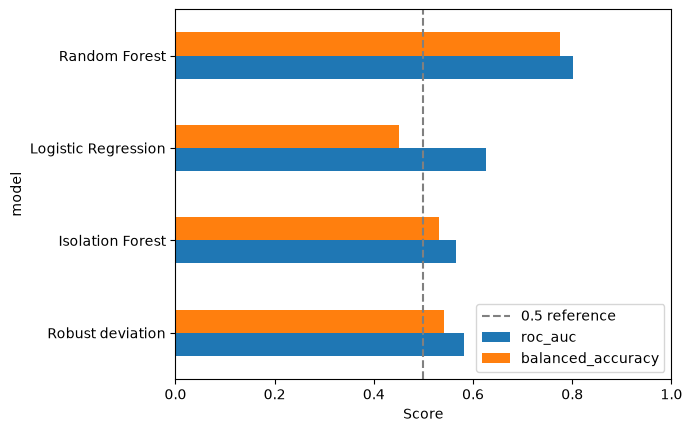

In [1]:
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

subprocess.run([sys.executable, "-m", "src.ml_baseline"], cwd=root, check=True, capture_output=True, text=True)
detection = pd.read_csv(root / "results/ml_detection.csv").set_index("model")
assert (detection[["tn", "fp", "fn", "tp"]].sum(axis=1) == 834).all()
display(detection.round(3))

ax = detection[["roc_auc", "balanced_accuracy"]].plot.barh(xlim=(0, 1))
ax.axvline(0.5, color="gray", linestyle="--", label="0.5 reference")
ax.set_xlabel("Score")
ax.legend()
plt.show()

## API error diagnosis

Train a Random Forest for each target. HTTP status groups the errors into 400, 401 and 404. The specific scenario target keeps each API error label separate. Both diagnosis tasks assume an error is already known. Compare top-1 accuracy with a majority-class baseline and use balanced accuracy to weight each test class equally. Top-3 accuracy is reported for specific scenarios.

In [2]:
diagnosis = pd.read_csv(root / "results/ml_diagnosis.csv").set_index("target")
assert diagnosis.loc["HTTP status", "training_classes"] == 3
assert diagnosis.loc["API error scenario", "training_classes"] == 53
display(diagnosis.round(3))

,training_classes,test_classes,test_windows,majority_top1_accuracy,top1_accuracy,balanced_accuracy,top3_accuracy
target,,,,,,,
HTTP status,3,3,823,0.547,0.567,0.442,NaN
API error scenario,53,53,823,0.018,0.079,0.082,0.204
